In [6]:
from pathlib import Path
import re
import json 

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

In [114]:
font_size = 12
matplotlib.rcParams['font.size'] = font_size
matplotlib.rcParams["font.weight"] = "bold"
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['axes.labelsize'] = font_size
matplotlib.rcParams['axes.titlesize'] = font_size
matplotlib.rcParams['legend.fontsize'] = font_size
matplotlib.rcParams['xtick.labelsize'] = font_size
matplotlib.rcParams['ytick.labelsize'] = font_size
#matplotlib.rcParams['text.latex.preamble']=r'\usepackage{amsmath} \DeclareMathOperator{\F}{F} \DeclareMathOperator{\GMF}{GMF} \DeclareMathOperator{\MLP}{MLP}'

In [8]:
def read_tb_file(tb_file):
    ea = event_accumulator.EventAccumulator(str(tb_file),
                                            size_guidance={ 
                                                event_accumulator.COMPRESSED_HISTOGRAMS: 0,
                                                event_accumulator.IMAGES: 0,
                                                event_accumulator.AUDIO: 0,
                                                event_accumulator.SCALARS: 0,
                                                event_accumulator.HISTOGRAMS: 0,})
    ea.Reload()
    return ea

def create_df_from_ea(ea, tag):
    steps = [x.step for x in ea.Scalars(tag)]
    values = [x.value for x in ea.Scalars(tag)]
    t0 = ea.Scalars(tag)[0].wall_time
    time = [x.wall_time-t0 for x in ea.Scalars(tag)]

    df = pd.DataFrame({"Time": time, "Step": steps, "Value": values})
    return df

def get_hparams_from_ea(ea):
    hparams_string = ea.Tensors('hyperparameters/text_summary')[0][2].string_val[0].decode()
    hparams_l = hparams_string.replace('|\n|',',').replace('|',':').replace(':param:value,-:-,','').split(',')
    keys = [i.split(':')[0] for i in hparams_l if len(i.split(':'))>1]
    values = [i.split(':')[1] for i in hparams_l if len(i.split(':'))>1]
        
    d = {k:v for k,v in zip(keys,values)}
    
    return d

def create_mu_std_df_from_ea(ea_dict, tag, filter_best=False, n_best=5):
    min_len = 1e6
    
    df_list = []
    for name, ea in ea_dict.items():
        df = create_df_from_ea(ea, tag)
        if len(df) < min_len:
            min_len = len(df)
        df_list.append(df)

    return create_mu_std_df(df_list, filter_best, n_best)

def create_mu_std_df(df_list, filter_best=False, n_best=5):
    print(df_list)
    val_list = []
    for df in df_list:
        val_list.append(df["Value"])
    val_list = np.array(val_list)
    
    means = np.mean(val_list, axis=-1)
    idx = np.argsort(-means)
    if filter_best:
        vals = val_list[idx[:n_best]]
    else:
        vals = val_list
    x_axis = df_list[0]["Step"][:min_len]
    
    mu = np.mean(vals, axis=0)
    median = np.median(vals, axis=0)
    std = np.std(vals, axis=0)
    q1 = np.quantile(vals, 0.25, axis=0)
    q3 = np.quantile(vals, 0.75, axis=0)
    best = val_list[idx[0]]
    return pd.DataFrame({"Step": x_axis, "mu": mu, "std": std, "best": best, "median": median, "q1": q1, "q3": q3})

def load_dirs(tasks_dir, tags, save_path=None):
    # init dicts
    df_dict = {}
    for tag in tags:
        df_dict[tag] = {}
        
    for task_dir in tqdm(tasks_dir.iterdir()):        
        ea_dict = {}

        if len(list((task_dir).iterdir())) > 0:
            try:
                ea_dict[task_dir] = read_tb_file(task_dir)
            except:
                print(f"WARNING: No data in {run_dir}. Skipped.")
                continue

        if ea_dict:
            for tag in tags:
                df_dict[tag][task_dir.name] = create_mu_std_df(
                    ea_dict, tag, filter_best=True, n_best=5).copy()
    
    if save_path:
        with open(save_path, 'wb') as handle:
            pkl.dump(df_dict, handle, protocol=pkl.HIGHEST_PROTOCOL)
    return df_dict

def plot_mu_std(x_axis, mu, q1=None, q3=None, std=None, fig=None, title=None, label='', yuplim=None, 
                ydownlim=None, interpolate=False, max_num_tasks=None):
    if fig is None:
        fig = plt.figure(figsize=[12,10])
        
    if interpolate:
        from scipy.interpolate import make_interp_spline, BSpline
        std = std[::2]
        new_size = std.shape[0]
        
        xnew = np.linspace(x_axis.min(), x_axis.max(), new_size)
        spl = make_interp_spline(x_axis, mu, k=3)  # type: BSpline
        power_smooth = spl(xnew)
        
        x_axis = xnew
        power_smooth = np.clip(power_smooth, np.min(mu), np.max(mu))
        mu = power_smooth

    if std is not None:
        uperror = mu+std
        downerror = mu-std
        
        uperror = np.clip(uperror, np.min(mu), np.max(mu))
        downerror = np.clip(downerror, np.min(mu), np.max(mu))
    else:
        uperror = q3
        downerror = q1    
    
    if yuplim is not None:
        uperror = np.where(uperror > yuplim, yuplim, uperror)
    if ydownlim is not None:
        downerror = np.where(downerror < ydownlim, ydownlim, downerror)
    plt.plot(x_axis, mu, label=label)
    plt.fill_between(x_axis, downerror, uperror, alpha=.1)
    plt.xlabel("Timesteps", fontsize=16)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    
    if title is not None:
        plt.title(title)

#     plt.ticklabel_format(axis="x", style="sci", scilimits=(0,0))
    if max_num_tasks:
        plt.yticks(np.arange(max_num_tasks+1), 
                   ["{0:1.1f}\%".format(100.0 * i/max_num_tasks) for i in np.arange(max_num_tasks+1)])
#     plt.legend(loc="lower right")
#     plt.legend(loc="upper left")
    
    return fig

def create_mean_std_plot(ea_dict, tag,  title, smoothing=3.0, savefig_fmt=None, filter_best=False):
    df = create_mu_std_df(ea_dict, tag)
    fig = plot_mu_std(title, 'forward',df["steps"], df["mu"], df["std"])
    if savefig_fmt is not None:
        plt.savefig(title + '.' + savefig_fmt, format=savefig_fmt, dpi=300)
        
    return fig

def parse_fname(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)
    seed = intgr[-4]
    n_epc = intgr[-1]
    n_epi = intgr[-2]
    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0
        
    return int(seed), float(irm_coeff), name

In [9]:
tags = ["charts/episodic_return"]
run_dir_swil = Path("runs/1708_maxswil")


In [ ]:
ea_dict_airl = {}
ea_dict_gail = {}
ea_dict_swil = {}

def load_to_dict(p):
    print(p)
    ea = read_tb_file(p)
    if 'airl' in str(p):
        ea_dict_airl[p] = ea
    elif 'gail' in str(p):
        ea_dict_gail[p] = ea
    else:
        ea_dict_swil[p] = ea
    
    return ea 

with ThreadPoolExecutor(20) as executor:
    futures = [executor.submit(load_to_dict, p) for p in run_dir_swil.iterdir()]

for f in futures:
    print(f.result())

In [12]:
len(ea_dict_swil.keys())

4326

In [14]:
list(ea_dict_swil.keys())[100]

PosixPath('runs/1708_maxswil/20230817_122206_467839_HalfCheetah-v3__ppo_swil_seed_234_np1_ua__seed_234__n_proj_1__n_demos_25__use_dones_True__use_next_obs_True__verbose_True')

In [95]:
seeds = [515, 234, 894, 322, 72]
algos = ['ppo']
disc_types = ['swil']
n_projs = [1,20,100]
envs = ['Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3']
lins = ['--linear_proj', '--use_weight_norm', '', '--use_weight_norm--linear_proj']
#lins = ['--use_weight_norm --linear_proj']
usenobs = ['--use_next_obs', '', '--use_next_obs--use_dones']

use_acs = ['']
n_demos = [1,4,10,25]
ent_coeffs = [0.0]
disc_nonlins = ['tanh', 'leakyrelu']

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for n_proj in n_projs:
            d[env_name][seed][f"np_{n_proj}"] = {}
            for n_demo in n_demos:
                d[env_name][seed][f"np_{n_proj}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][seed][f"np_{n_proj}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][seed][f"np_{n_proj}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][seed][f"np_{n_proj}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}

                            
                        
def parse_fname_irm(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    m = re.search('irm(\d+)', fname, re.IGNORECASE)
    irm = int(m.group(1))

    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0

    return int(seed), float(irm_coeff), name

def parse_fname_il(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    np = re.search('np(\d+)', fname, re.IGNORECASE)
    np = int(np.group(1))
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), np, name

### [170823_maxswil] Load data into result dict

In [119]:
for k, v in ea_dict_swil.items():
    hparams = get_hparams_from_ea(v)
    lin_string = ""
    if hparams['use_weight_norm'] == 'True':
        lin_string += "--use_weight_norm"
    if hparams['linear_proj'] == 'True':
        lin_string += "--linear_proj"

    nob_string = ""
    if hparams['use_next_obs'] == 'True':
        nob_string += "--use_next_obs"
    if hparams['use_dones'] == 'True':
        nob_string += "--use_dones"
    
    
    seed, np, name = parse_fname_il(str(k))
    n_proj = f"np_{hparams['n_proj']}"
    n_demos = f"nd_{hparams['n_demos']}"
    env_name = name[0]+'3'
    
    d_nl = hparams['disc_nonlin']
    #print(env_name, seed, n_proj, n_demos, lin_string, nob_string, d_nl)
    d[env_name][seed][n_proj][n_demos][lin_string][nob_string][d_nl] = v


/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_13513/672317892.py:14: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, axs = plt.subplots(1,3, figsize=(20,4))


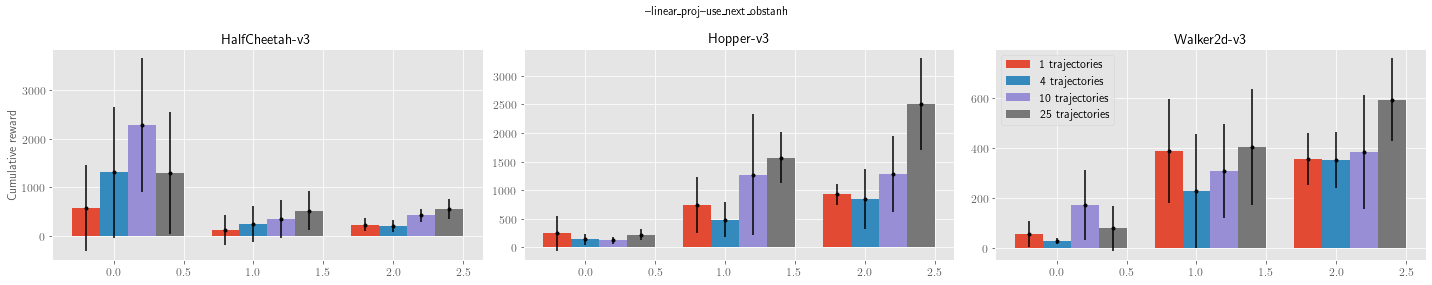

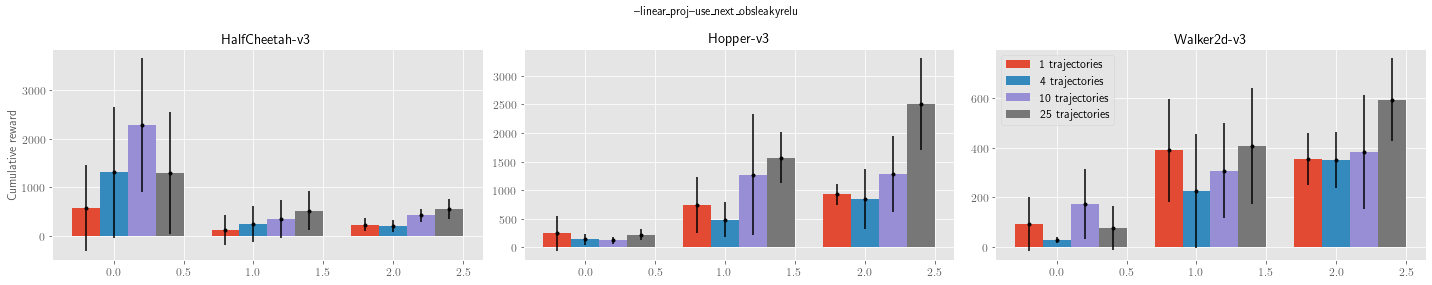

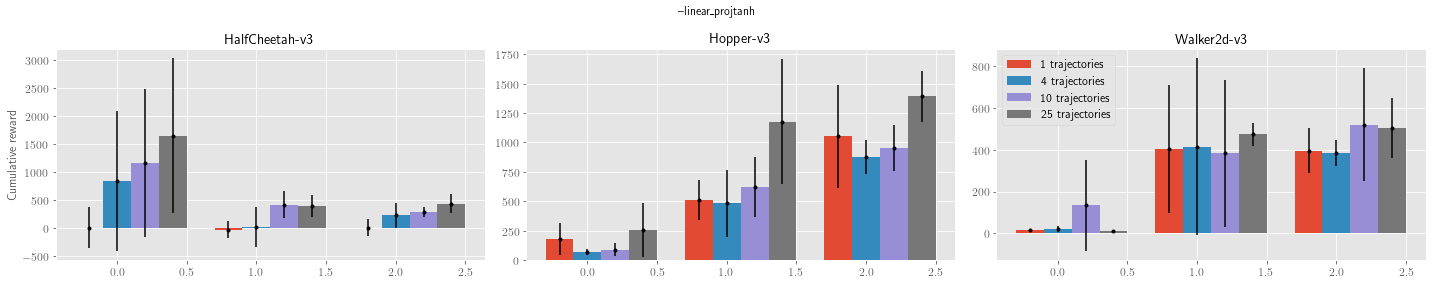

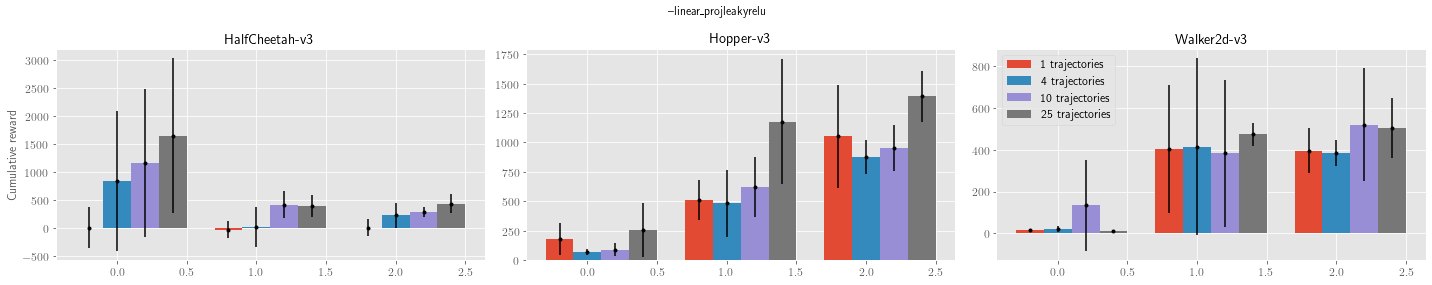

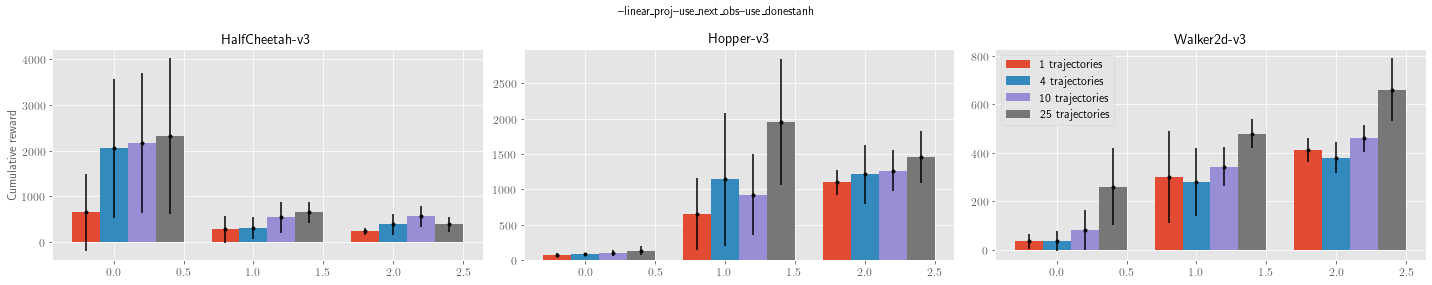

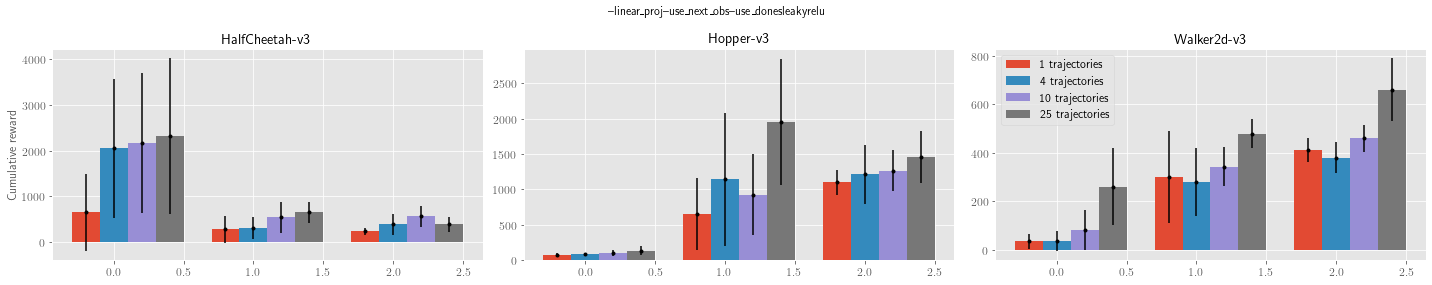

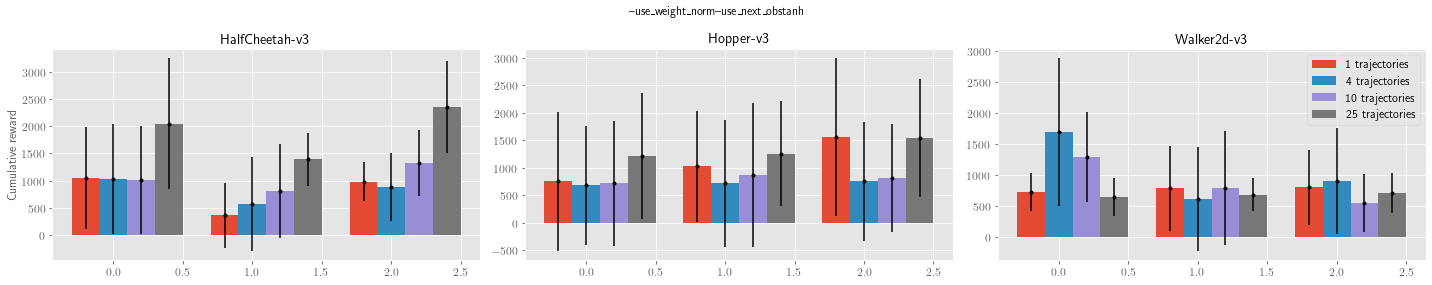

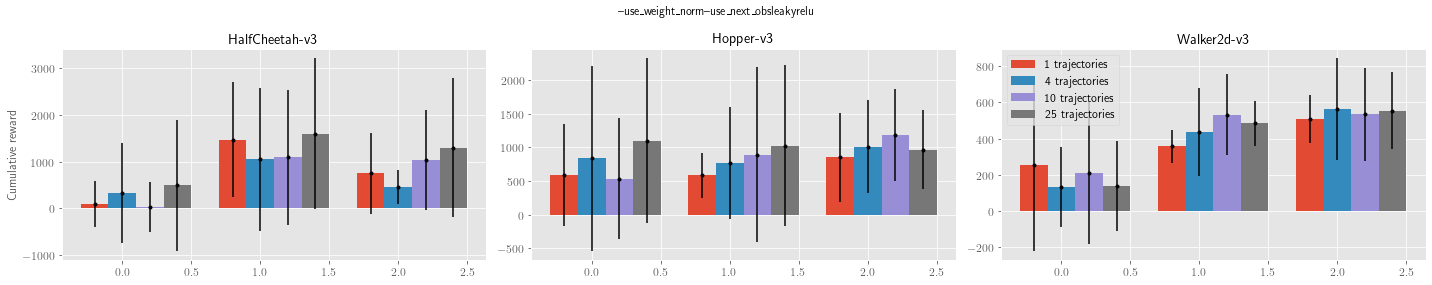

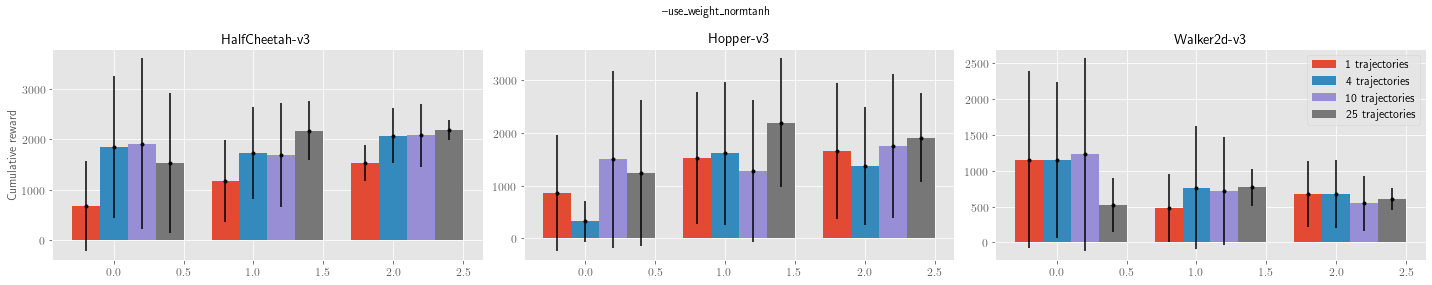

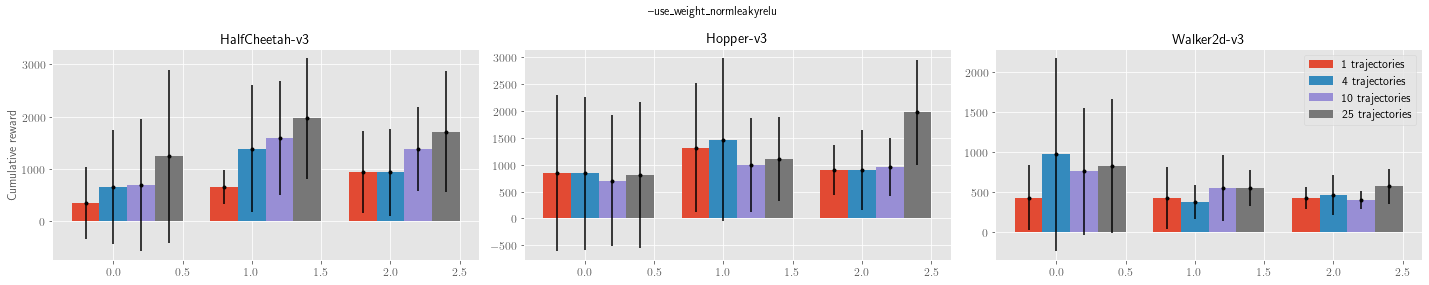

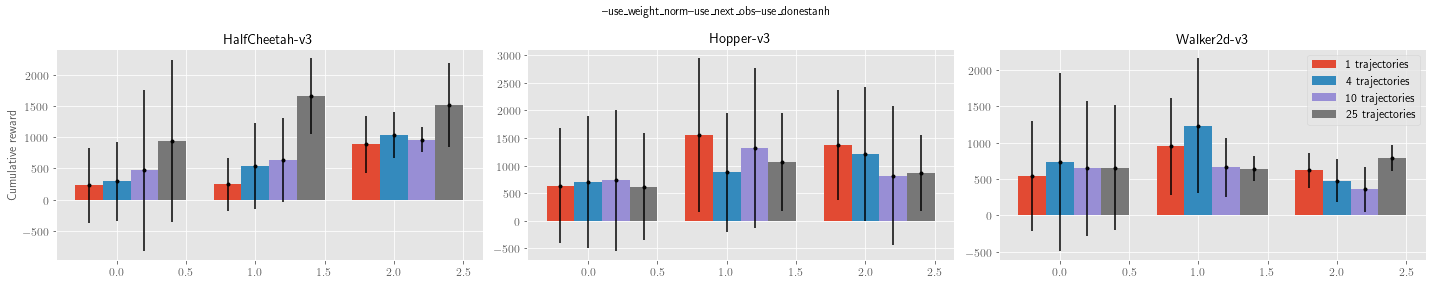

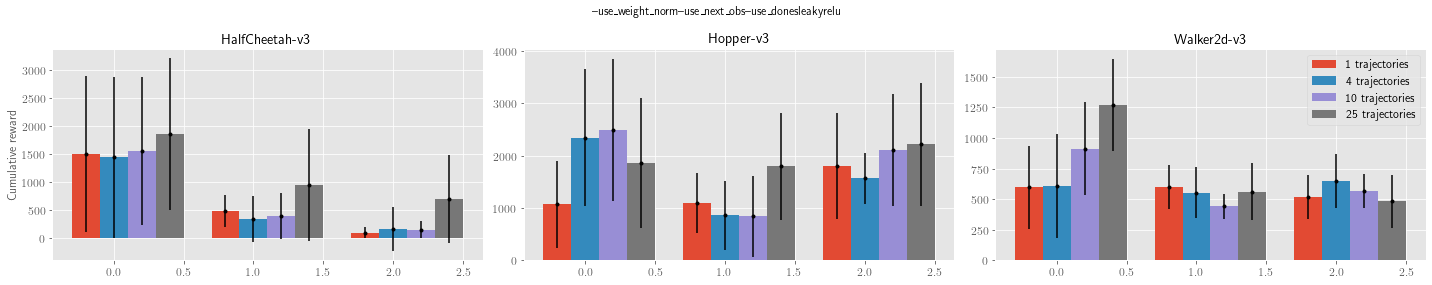

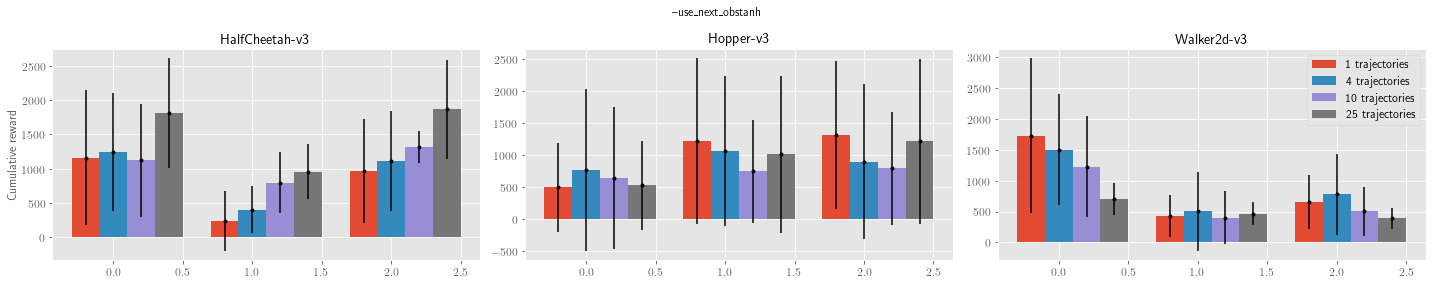

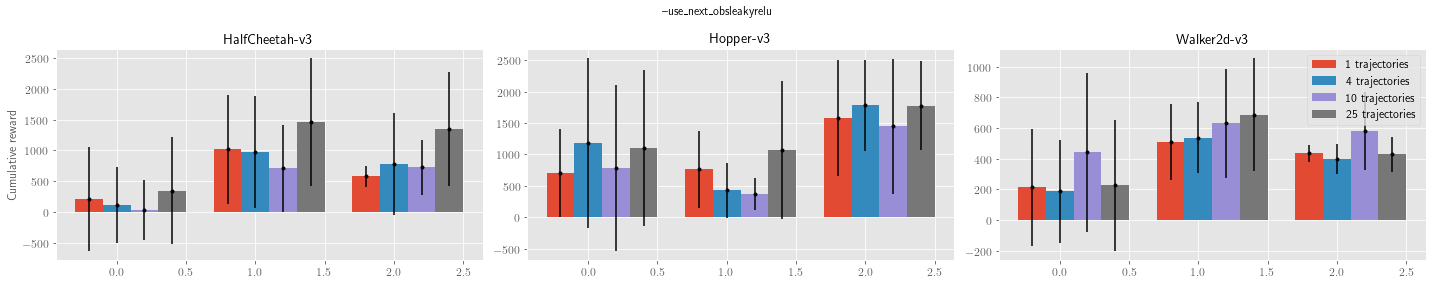

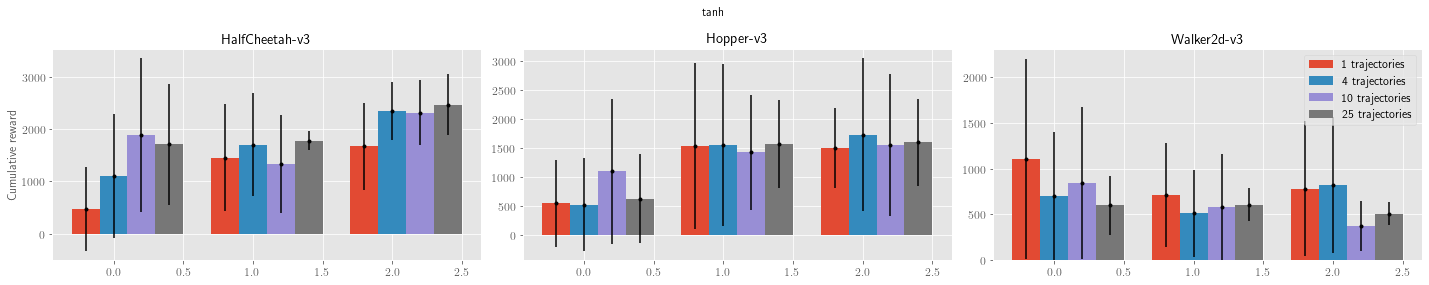

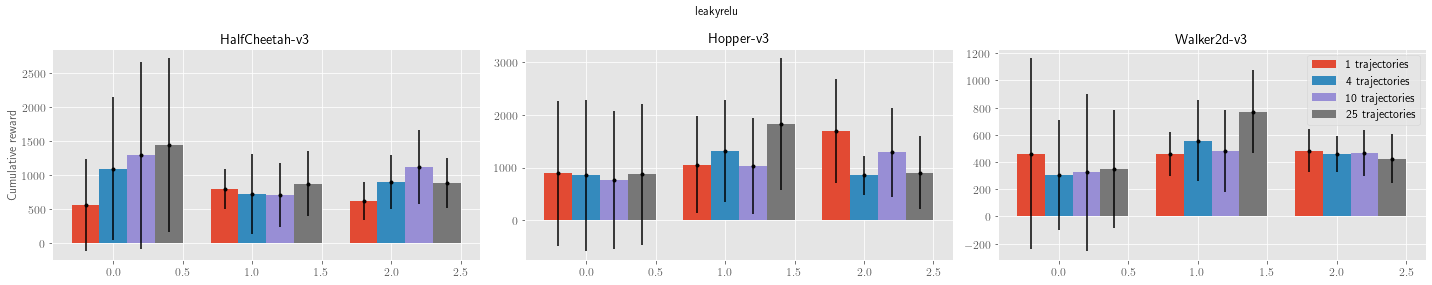

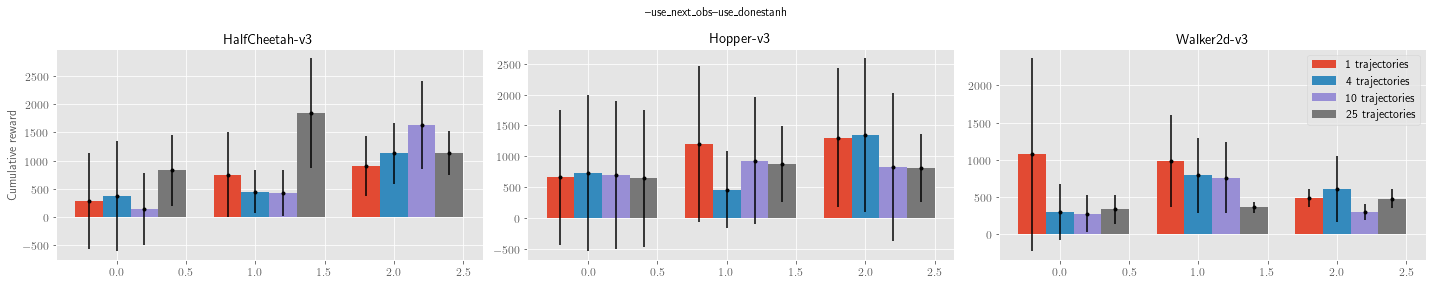

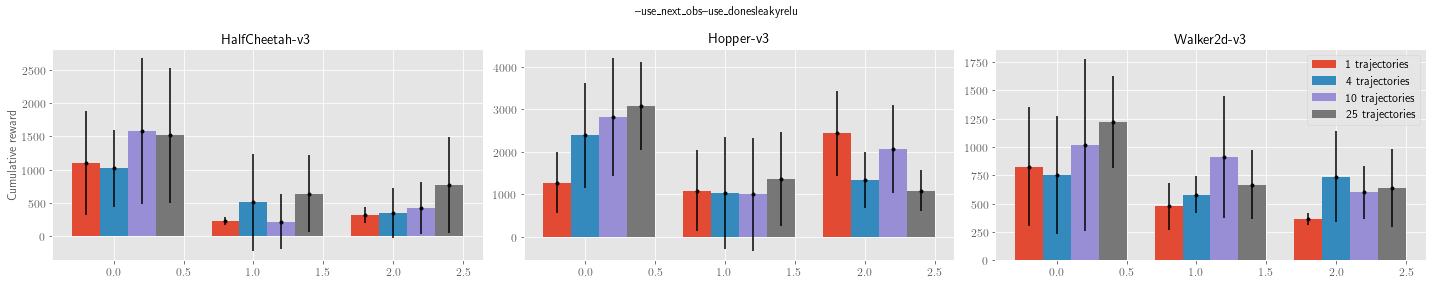

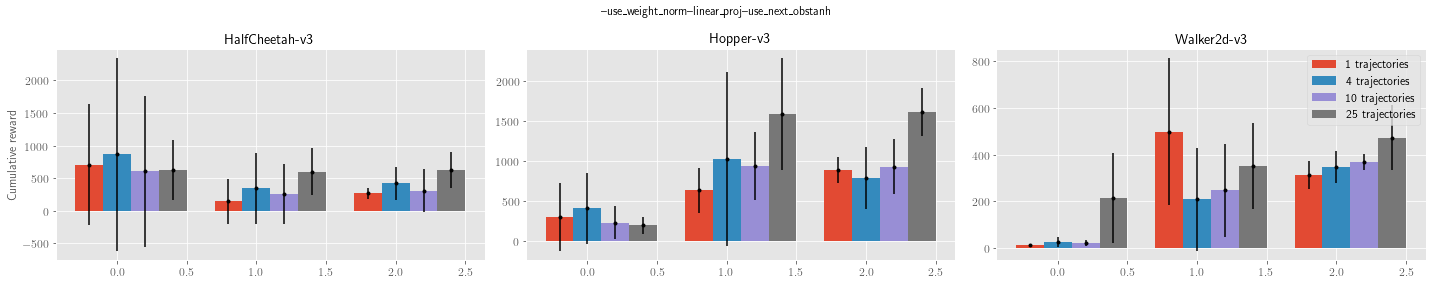

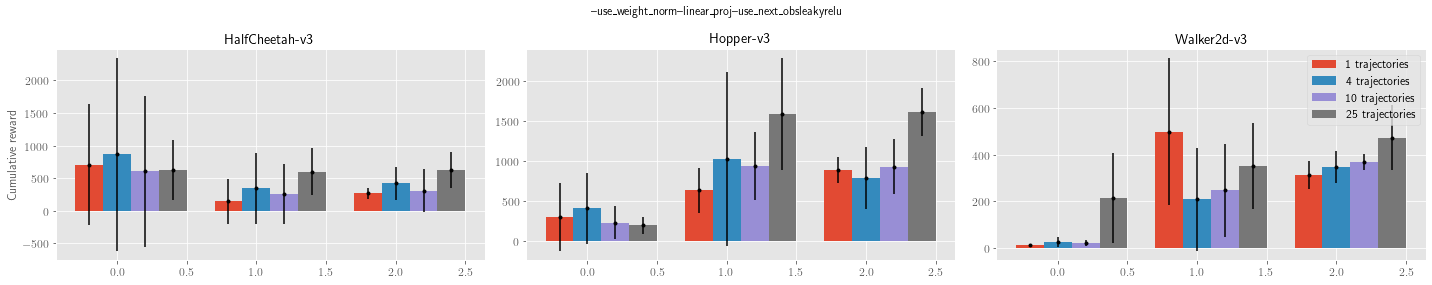

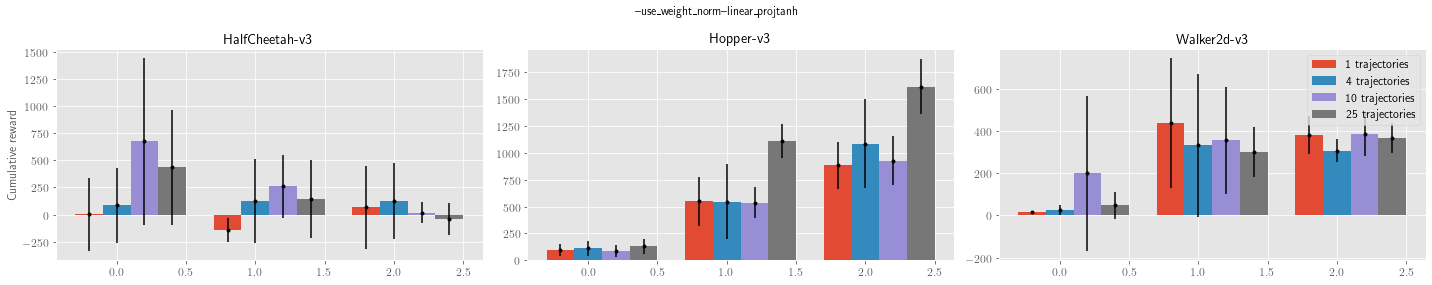

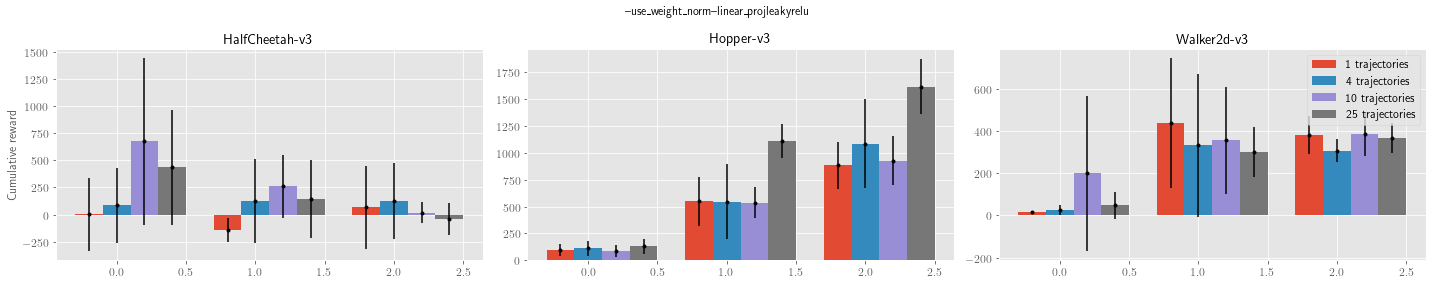

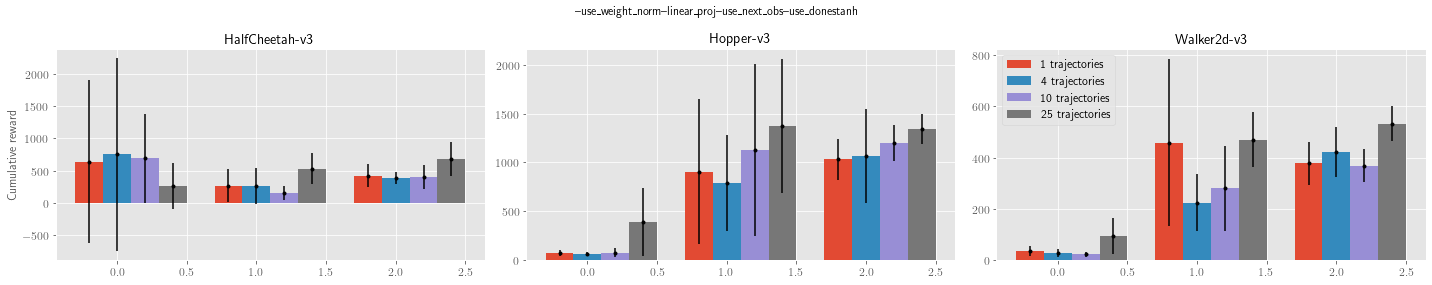

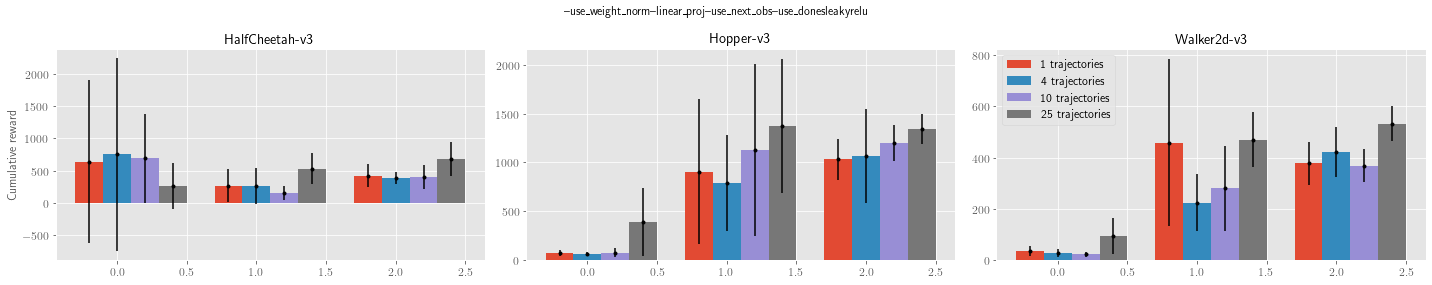

In [120]:
import numpy as np
df_dict_swil = d
#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''
lins = ['--linear_proj', '--use_weight_norm', '', '--use_weight_norm--linear_proj']
#lins = ['--linear_proj', '--use_weight_norm--linear_proj']
usenobs = ['--use_next_obs', '', '--use_next_obs--use_dones']
disc_nonlins = ['tanh', 'leakyrelu']

for lin in lins:
    for nob in usenobs:
        for nonlin in disc_nonlins:
            fig, axs = plt.subplots(1,3, figsize=(20,4))
            fig.subplots_adjust(top=0.88)
            fig.suptitle(lin + nob + nonlin)
            plt.style.use('ggplot')
            #print(lin, nob, nonlin)
            #plt.title(lin + nob + nonlin)

            for i, env in enumerate(['HalfCheetah-v3', 'Hopper-v3', 'Walker2d-v3']):
                X = ['swil:np1','swil:np20','swil:np100']
                X_axis = np.arange(len(X))
                axs[i].set_title(env)
                for j,nd in enumerate([1,4,10,25]):
                    Y = []
                    Y_ = []

                    n_proj = [1,20,100]
                    for n_p in n_proj: 
                        val_list = []
                        for seed in [515, 234, 894, 322, 72]:
                            ea = df_dict_swil[env][seed][f"np_{n_p}"][f"nd_{nd}"][lin][nob][nonlin]
                            if not isinstance(ea,dict):
                                df = create_df_from_ea(ea, tags[0])
                                val_list.append(np.max(df['Value']))

                        if len(val_list) > 0:
                            Y.append(np.mean(val_list))
                            Y_.append(np.std(val_list))
                        else:
                            Y.append(0)            
                            Y_.append(0)

                    #print(Y, Y_)

                    axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2, label=f"{nd} trajectories") 
                    axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

            axs[0].set_ylabel("Cumulative reward")

            plt.legend()
            plt.tight_layout()

['gail', 'airl', 'swil:np1', 'swil:np5', 'swil:np20', 'swil:np50']


NameError: name 'df_dict_gail' is not defined

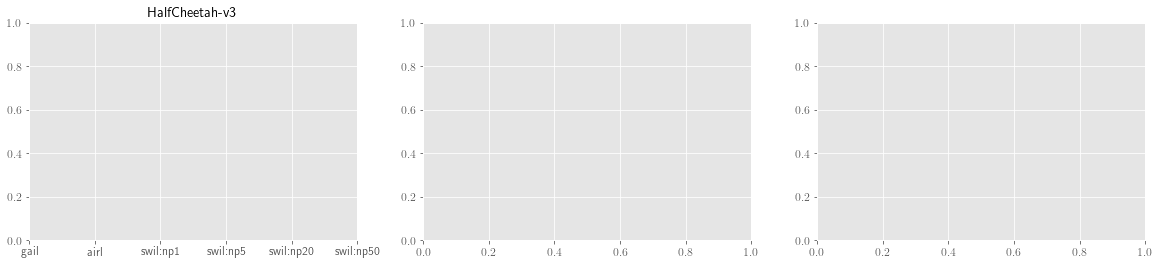

In [117]:
fig, axs = plt.subplots(1,3, figsize=(20,4))
nonlin="prelu"
plt.style.use('ggplot')

for i, env in enumerate(['HalfCheetah-v3', 'Hopper-v3', 'Walker2d-v3']):
    X = ['gail','airl','swil:np1','swil:np5','swil:np20','swil:np50']
    X_axis = np.arange(len(X))

    axs[i].set_title(env)
    #plt.gca()
    #plt.xticks(X_axis, X)
    print(X)
    axs[i].set_xticks(X_axis,X)

    for j,nd in enumerate([1,4,10,25]):
        Y = []
        Y_ = []
        gail_val = list(df_dict_gail[1]['ppo'][env][0.0][nd][nonlin].values())
        airl_val = list(df_dict_airl[1]['ppo'][env][0.0][nd][nonlin].values())
        if len(gail_val) > 0:
            Y.append(np.mean(gail_val))
            Y_.append(np.std(gail_val))
        else:
            Y.append(0)
            Y_.append(0)
        
        if len(airl_val) > 0:
            Y.append(np.mean(airl_val))
            Y_.append(np.std(airl_val))
        else:
            Y.append(0)
            Y_.append(0)

        n_proj = [1,5,20,50]
        for n_p in n_proj:
            swil_val = list(df_dict_swil[1]['ppo'][env][n_p][nd][nonlin].values())
            if len(swil_val) > 0:
                Y.append(np.mean(swil_val))
                Y_.append(np.std(swil_val))
            else:
                Y.append(0)            
                Y_.append(0)
                
        print(Y, Y_)
                
        axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2, label=f"{nd} trajectories") 
        axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

        #plt.gca()
        #plt.xticks(X_axis, X)

axs[0].set_ylabel("Cumulative reward")
